In [1]:
import anndata
from anndata import AnnData
import pandas as pd
import rectanglepy as rp
import matplotlib.pyplot as plt
from scipy.io import mmread
from scipy.sparse import csr_matrix
import helper

import re



# Figure 4

## Figure 4A


Load the data

In [28]:
gld = pd.read_excel("../data/fig4/luca_cancer.xlsx", index_col=0)
gld = gld.fillna(0)
gld = gld[gld["Cancer type"] == "BRCA"]

gld = gld.drop(columns=["Unnamed: 7", "Cancer type"])
gld.index = gld.index.str.replace("-", ".")
# Create a new column 'sample_name' that contains the sample names without the last character
gld['sample_name'] = gld.index.str[:-1]

# Group the rows based on the 'sample_name' column and calculate the mean for each group
df_grouped = gld.groupby('sample_name').mean()

/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


### Brca data

In [5]:
annotations_brca = pd.read_csv("../data/fig4/brca_nocycling_annotations.csv", index_col=0)
sc_data_brca = pd.read_csv("../data/fig4/brca_nocycline_counts.csv", index_col=0)
bulks_brca = pd.read_csv("../data/fig4/TCGA_tpm_BRCA.txt", sep="\t")

ribsosomal_gene_re = r"^RP[SL]|^RP\d|^RPSA"
# remove ribosomal genes from bulk and scRNA-seq data
sc_data_brca = sc_data_brca[~sc_data_brca.index.str.match(ribsosomal_gene_re)]
bulks_brca = bulks_brca[~bulks_brca.index.str.match(ribsosomal_gene_re)]


annotations_brca.index = sc_data_brca.columns
annotations = pd.Series(annotations_brca["x"])

adata_brca = AnnData(sc_data_brca.T, obs=annotations.to_frame(name="cell_type"))
adata_brca = adata_brca[adata_brca.obs['cell_type'] != 'Normal Epithelial']
adata_brca_no_cancer = adata_brca[adata_brca.obs['cell_type'] != 'Cancer Epithelial']


In [ ]:
# rsults with cancer ce
brca_estimations, signature_results_brca = rp.rectangle(adata_brca, bulks_brca.T)
brca_estimations.to_csv("../output/brca_estimations.csv")


In [ ]:
brca_estimations_no_cancer, signature_results_brca_no_cancer = rp.rectangle(adata_brca_no_cancer, bulks_brca.T)
brca_estimations_no_cancer.to_csv("../output/brca_estimations_no_cancer.csv")

In [18]:
# Unknown  and Cancer Epithelial
brca_estimations = pd.read_csv("../output/brca_estimations.csv", index_col=0)
brca_estimations.index = brca_estimations.index.str.replace("-", ".")
brca_estimations['CPE'] = brca_estimations['Unknown'] + brca_estimations['Cancer Epithelial']
brca_estimations_m, gld_m = helper.match_dfs(brca_estimations, df_grouped)
evaluation_brca = helper.create_evaluation_df(gld_m.T, brca_estimations_m.T)
rsme_brca, r_brca, p_brca= helper.evaulate_total_df(evaluation_brca)

# Just Cancer
brca_estimations = pd.read_csv("../output/brca_estimations.csv", index_col=0)
brca_estimations.index = brca_estimations.index.str.replace("-", ".")
brca_estimations['CPE'] = brca_estimations['Cancer Epithelial']
brca_estimations_m, gld_m_cancer = helper.match_dfs(brca_estimations, df_grouped)
evaluation_brca_cancer = helper.create_evaluation_df(gld_m_cancer.T, brca_estimations_m.T)
rsme_brca_cancer, r_brca_cancer, p_brca = helper.evaulate_total_df(evaluation_brca_cancer)

# Just Unkwnown
brca_estimations_no_cancer = pd.read_csv("../output/brca_estimations_no_cancer.csv", index_col=0)
brca_estimations_no_cancer.index = brca_estimations_no_cancer.index.str.replace("-", ".")
brca_estimations_no_cancer['CPE'] =  brca_estimations_no_cancer['Unknown']
brca_estimations_no_cancer_m, gld_m_no_cancer = helper.match_dfs(brca_estimations_no_cancer, df_grouped)
evaluation_brca_no_cancer = helper.create_evaluation_df(gld_m_no_cancer.T, brca_estimations_no_cancer_m.T)
rsme_brca_no_cancer, r_brca_no_cancer, p_brca_no_cancer = helper.evaulate_total_df(evaluation_brca_no_cancer)

### Luad + Lusc data

In [31]:
gld = pd.read_excel("../data/fig4/luca_cancer.xlsx", index_col=0)
gld = gld.fillna(0)
gld = gld.drop(columns=["Unnamed: 7", "Cancer type"])
gld.index = gld.index.str.replace("-", ".")
# Create a new column 'sample_name' that contains the sample names without the last character
gld['sample_name'] = gld.index.str[:-1]

# Group the rows based on the 'sample_name' column and calculate the mean for each group
df_grouped = gld.groupby('sample_name').mean()


gld.to_csv("./luca_gld.csv")

/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


In [23]:
luad_bulk = pd.read_csv("../data/fig4/luad.csv", index_col=0)
lusc_bulk = pd.read_csv("../data/fig4/lusc.csv", index_col=0)

luca_sd = anndata.read_h5ad("../data/fig4/lambrechts.h5ad")
luca_sd = luca_sd[luca_sd.obs['cell_type'] != 'Epithelial cells']
luca_sd_no_cancer = luca_sd[luca_sd.obs['cell_type'] != 'Tumor cells']

# remove ribosomal genes from bulk is enough since rectangle matches the genes
ribsosomal_gene_re = r"^RP[SL]|^RP\d|^RPSA"
luad_bulk = luad_bulk[~luad_bulk.index.str.match(ribsosomal_gene_re)]
lusc_bulk = lusc_bulk[~lusc_bulk.index.str.match(ribsosomal_gene_re)]


In [ ]:
luad_estimations, signature_results_luad = rp.rectangle(luca_sd, luad_bulk.T)
luad_estimations.to_csv("../output/luad_estimations.csv")

lusc_estimations, signature_results_lusc = rp.rectangle(luca_sd, lusc_bulk.T)
lusc_estimations.to_csv("../output/lusc_estimations.csv")

In [ ]:
luad_estimations_no_cancer, signature_results_luad_no_cancer = rp.rectangle(luca_sd_no_cancer, luad_bulk.T)
luad_estimations_no_cancer.to_csv("../output/luad_estimations_no_cancer.csv")
lusc_estimations_no_cancer, signature_results_lusc_no_cancer = rp.rectangle(luca_sd_no_cancer, lusc_bulk.T)
lusc_estimations_no_cancer.to_csv("../output/lusc_estimations_no_cancer.csv")

In [33]:
luad_estimations = pd.read_csv("../output/luad_estimations.csv", index_col=0)
luad_estimations['CPE'] = luad_estimations['Unknown'] + luad_estimations['Tumor cells']
luad_estimations_m, luad_gld_m = helper.match_dfs(luad_estimations, df_grouped)
evaluation_luad = helper.create_evaluation_df(luad_gld_m.T, luad_estimations_m.T)
rsme_luad, r_luad, p_luad = helper.evaulate_total_df(evaluation_luad)

# Just Tumor cells
luad_estimations = pd.read_csv("../output/luad_estimations.csv", index_col
=0)
luad_estimations['CPE'] = luad_estimations['Tumor cells']
luad_estimations_m, luad_gld_m_cancer = helper.match_dfs(luad_estimations, df_grouped)
evaluation_luad_cancer = helper.create_evaluation_df(luad_gld_m_cancer.T, luad_estimations_m.T)
rsme_luad_cancer, r_luad_cancer, p_luad = helper.evaulate_total_df(evaluation_luad_cancer)

# Just Unknown
luad_estimations_no_cancer = pd.read_csv("../output/luad_estimations_no_cancer.csv", index_col=0)
luad_estimations_no_cancer['CPE'] = luad_estimations_no_cancer['Unknown']
luad_estimations_no_cancer_m, luad_gld_m_no_cancer = helper.match_dfs(luad_estimations_no_cancer, df_grouped)
evaluation_luad_no_cancer = helper.create_evaluation_df(luad_gld_m_no_cancer.T, luad_estimations_no_cancer_m.T)
rsme_luad_no_cancer, r_luad_no_cancer, p_luad_no_cancer = helper.evaulate_total_df(evaluation_luad_no_cancer)

# LUSC: Unknown + Tumor cells
lusc_estimations = pd.read_csv("../output/lusc_estimations.csv", index_col=0)
lusc_estimations['CPE'] = lusc_estimations['Unknown'] + lusc_estimations['Tumor cells']
lusc_estimations_m, lusc_gld_m = helper.match_dfs(lusc_estimations, df_grouped)
evaluation_lusc = helper.create_evaluation_df(lusc_gld_m.T, lusc_estimations_m.T)
rsme_lusc, r_lusc, p_lusc = helper.evaulate_total_df(evaluation_lusc)

# LUSC: Just Tumor cells
lusc_estimations = pd.read_csv("../output/lusc_estimations.csv", index_col=0)
lusc_estimations['CPE'] = lusc_estimations['Tumor cells']
lusc_estimations_m, lusc_gld_m_cancer = helper.match_dfs(lusc_estimations, df_grouped)
evaluation_lusc_cancer = helper.create_evaluation_df(lusc_gld_m_cancer.T, lusc_estimations_m.T)
rsme_lusc_cancer, r_lusc_cancer, p_lusc = helper.evaulate_total_df(evaluation_lusc_cancer)

# LUSC: Just Unknown
lusc_estimations_no_cancer = pd.read_csv("../output/lusc_estimations_no_cancer.csv", index_col=0)
lusc_estimations_no_cancer['CPE'] = lusc_estimations_no_cancer['Unknown']
lusc_estimations_no_cancer_m, lusc_gld_m_no_cancer = helper.match_dfs(lusc_estimations_no_cancer, df_grouped)
evaluation_lusc_no_cancer = helper.create_evaluation_df(lusc_gld_m_no_cancer.T, lusc_estimations_no_cancer_m.T)
rsme_lusc_no_cancer, r_lusc_no_cancer, p_lusc_no_cancer = helper.evaulate_total_df(evaluation_lusc_no_cancer)





<Axes: title={'center': 'Tumor+Unkn'}, xlabel='Tumor purity', ylabel='Tumor + unknown cells'>

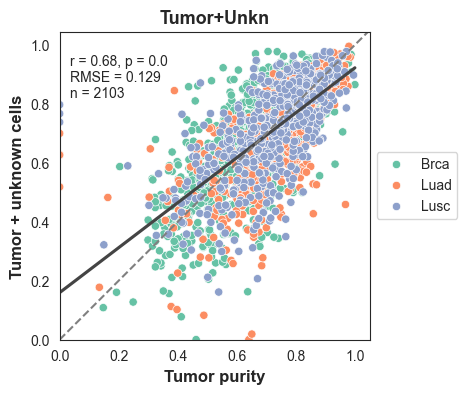

In [37]:

luad_estimations = pd.read_csv("../output/luad_estimations.csv", index_col=0)
luad_estimations['CPE'] = luad_estimations['Unknown'] + luad_estimations['Tumor cells']

lusc_estimations = pd.read_csv("../output/lusc_estimations.csv", index_col=0)
lusc_estimations['CPE'] = lusc_estimations['Unknown'] + lusc_estimations['Tumor cells']

brca_estimations = pd.read_csv("../output/brca_estimations.csv", index_col=0)
brca_estimations.index = brca_estimations.index.str.replace("-", ".")
brca_estimations['CPE'] = brca_estimations['Unknown'] + brca_estimations['Cancer Epithelial']


luad_estimations['data'] = 'Luad'
lusc_estimations['data'] = 'Lusc'
brca_estimations['data'] = 'Brca'

all = pd.concat([brca_estimations, luad_estimations, lusc_estimations])

all_m, gld_m = helper.match_dfs(all, df_grouped)

evaluation_all = helper.create_evaluation_df(gld_m.T, all_m.T)

evaluation_all['data'] = list(all['data'])

rsme_all, r_all, p_all = helper.evaulate_total_df(evaluation_all)

helper.create_scatter_plot_total(evaluation_all, rsme_all, p_all, r_all, 'Tumor+Unkn', y_axis_label="Tumor + unknown cells", x_axis_label="Tumor purity", hue='data', save_path='../figures/fig4a_all_tumor_and_unkn_new.pdf', size=(4, 4))

<Axes: title={'center': 'Tumor'}, xlabel='Tumor purity', ylabel='Tumor cells'>

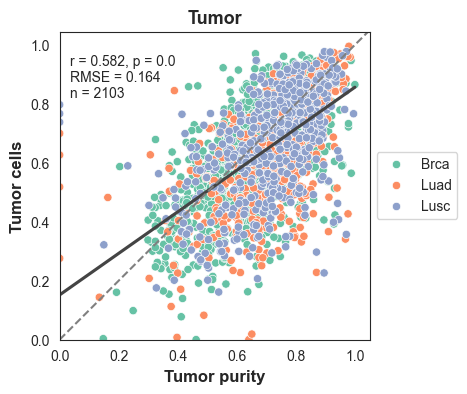

In [38]:
luad_estimations = pd.read_csv("../output/luad_estimations.csv", index_col=0)
luad_estimations['CPE'] = luad_estimations['Tumor cells']

lusc_estimations = pd.read_csv("../output/lusc_estimations.csv", index_col=0)
lusc_estimations['CPE'] = lusc_estimations['Tumor cells']

brca_estimations = pd.read_csv("../output/brca_estimations.csv", index_col=0)
brca_estimations.index = brca_estimations.index.str.replace("-", ".")
brca_estimations['CPE'] = brca_estimations['Cancer Epithelial']

luad_estimations['data'] = 'Luad'
lusc_estimations['data'] = 'Lusc'
brca_estimations['data'] = 'Brca'

all = pd.concat([brca_estimations, luad_estimations, lusc_estimations])

all_m, gld_m = helper.match_dfs(all, df_grouped)

evaluation_all = helper.create_evaluation_df(gld_m.T, all_m.T)

evaluation_all['data'] = list(all['data'])

rsme_all_t, r_all_t, p_all = helper.evaulate_total_df(evaluation_all)

helper.create_scatter_plot_total(evaluation_all, rsme_all_t, p_all, r_all_t, 'Tumor', y_axis_label="Tumor cells", x_axis_label="Tumor purity", hue='data', save_path='../figures/fig4a_all_tumor.pdf', size=(4, 4))

<Axes: title={'center': 'Unknown'}, xlabel='Tumor purity', ylabel='Unknown cells'>

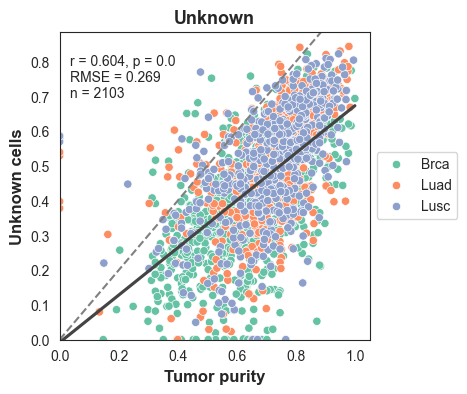

In [40]:
#no tumor
luad_estimations_no_cancer = pd.read_csv("../output/luad_estimations_no_cancer.csv", index_col=0)
luad_estimations_no_cancer['CPE'] = luad_estimations_no_cancer['Unknown']
lusc_estimations_no_cancer = pd.read_csv("../output/lusc_estimations_no_cancer.csv", index_col=0)
lusc_estimations_no_cancer['CPE'] = lusc_estimations_no_cancer['Unknown']
brca_estimations_no_cancer = pd.read_csv("../output/brca_estimations_no_cancer.csv", index_col=0)
brca_estimations_no_cancer.index = brca_estimations_no_cancer.index.str.replace("-", ".")
brca_estimations_no_cancer['CPE'] = brca_estimations_no_cancer['Unknown']

luad_estimations_no_cancer['data'] = 'Luad'
lusc_estimations_no_cancer['data'] = 'Lusc'
brca_estimations_no_cancer['data'] = 'Brca'

all_no_cancer = pd.concat([brca_estimations_no_cancer, luad_estimations_no_cancer, lusc_estimations_no_cancer])
all_no_cancer_m, gld_m_no_cancer = helper.match_dfs(all_no_cancer, df_grouped)
evaluation_all_no_cancer = helper.create_evaluation_df(gld_m_no_cancer.T, all_no_cancer_m.T)
evaluation_all_no_cancer['data'] = list(all_no_cancer['data'])
rsme_all_no_cancer, r_all_no_cancer, p_all_no_cancer = helper.evaulate_total_df(evaluation_all_no_cancer)

helper.create_scatter_plot_total(evaluation_all_no_cancer, rsme_all_no_cancer, p_all_no_cancer, r_all_no_cancer, 'Unknown', y_axis_label="Unknown cells", x_axis_label="Tumor purity", hue='data', save_path='../figures/fig4a_all_unkn.pdf', size=(4, 4))


## 4B

In [43]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Set style
sns.set_style('white')

# Data preparation
values_rsme = [rsme_brca, rsme_luad, rsme_lusc]
values_rsme_t = [rsme_brca_cancer, rsme_luad_cancer, rsme_lusc_cancer]
values_rsme_n = [rsme_brca_no_cancer, rsme_luad_no_cancer, rsme_lusc_no_cancer]

values_corr = [r_brca, r_luad, r_lusc]
values_corr_t = [r_brca_cancer, r_luad_cancer, r_lusc_cancer]
values_corr_n = [r_brca_no_cancer, r_luad_no_cancer, r_lusc_no_cancer]

# Create DataFrame
standard_df = pd.DataFrame({
    'RMSE': values_rsme,
    'Correlation': values_corr,
    'Dataset': ['Brca', 'Luad', 'Lusc'],
    'Condition': ['Tumor+Unkn'] * 3
})

tumor_df = pd.DataFrame({
    'RMSE': values_rsme_t,
    'Correlation': values_corr_t,
    'Dataset': ['Brca', 'Luad', 'Lusc'],
    'Condition': ['Tumor'] * 3
})

unknown_df = pd.DataFrame({
    'RMSE': values_rsme_n,
    'Correlation': values_corr_n,
    'Dataset': ['Brca', 'Luad', 'Lusc'],
    'Condition': ['Unkn'] * 3
})

# Concatenate the DataFrames
df = pd.concat([standard_df, tumor_df, unknown_df])



In [1]:
import seaborn as sns

import matplotlib.pyplot as plt
import pandas as pd

sns.set_theme("notebook")
sns.set_style('ticks')
# Set a color palette
color_palette =  ['#66C2A5','#FC8D62','#8DA0CB']

# Combine the data into a single DataFrame
df_combined = pd.DataFrame({
    'RMSE': values_rsme + values_rsme_t + values_rsme_n,
    'Correlation': values_corr + values_corr_t + values_corr_n,
    'Condition': ['Tumor+Unkn'] * 3 + ['Tumor'] * 3 + ['Unkn'] * 3,
    'Dataset': ['Brca', 'Luad', 'Lusc'] * 3
})

# Create the scatter plot
plt.figure(figsize=(3, 3))
ax = sns.scatterplot(data=df_combined, x='RMSE', y='Correlation', hue='Dataset', style='Condition', s=100, palette=color_palette)
plt.title('RMSE vs Correlation')

# Custom legend with two columns: Dataset and Condition
handles, labels = ax.get_legend_handles_labels()
# The first handle/label is for the title, skip it
handles = handles[1:]
labels = labels[1:]

# Remove duplicate legend entries
plt.legend(list(legend_dict.values()), list(legend_dict.keys()), ncol=2, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

plt.savefig('../figures/fig4b_all_unkn_comparison_scatter.pdf', bbox_inches='tight', dpi=300)
plt.show()


NameError: name 'values_rsme' is not defined

In [1]:
## 4C

In [19]:
unknown_content_results = pd.read_csv("../data/fig4/unknown_content_results.csv", index_col=0)
distinct_fractions = [0.1 , 0.2 , 0.3 , 0.5 , 0.7 , 0.9 , 0.  ]
unknown_content_results = unknown_content_results[unknown_content_results['unknown_fraction'].isin(distinct_fractions)]

# Rename methods to match method_palette capitalization
method_mapping = {
    'autogenes': 'AutoGeneS',
    'bayesprism': 'BayesPrism',
    'bisque': 'Bisque',
    'cibersortx': 'CIBERSORTx',
    'dwls': 'DWLS',
    'music': 'MuSiC',
    'scaden': 'Scaden',
    'scdc': 'SCDC',
    'rectangle': 'Rectangle'
}
unknown_content_results['method'] = unknown_content_results['method'].replace(method_mapping)

In [20]:
from scipy import stats

# Correlation results grouped by celltype, method, replicate, dataset, unknown_fraction
correlation_results = unknown_content_results.groupby(['celltype', 'method', 'replicate', 'dataset', 'unknown_fraction']).apply(
    lambda x: pd.Series({
        'corr': stats.pearsonr(x['true_value'], x['predicted_value'])[0],
        'pval': stats.pearsonr(x['true_value'], x['predicted_value'])[1]
    })
).reset_index()

# Correlation results for all cells grouped by method, replicate, dataset, unknown_fraction
correlation_results_all = unknown_content_results.groupby(['method', 'replicate', 'dataset', 'unknown_fraction']).apply(
    lambda x: pd.Series({
        'corr': stats.pearsonr(x['true_value'], x['predicted_value'])[0],
        'pval': stats.pearsonr(x['true_value'], x['predicted_value'])[1]
    })
).reset_index()
correlation_results_all['celltype'] = 'all-cells'

# Correlation results for all cells grouped by method, dataset, unknown_fraction (no replicate)
cor_results_all = unknown_content_results.groupby(['method', 'dataset', 'unknown_fraction']).apply(
    lambda x: pd.Series({
        'corr': stats.pearsonr(x['true_value'], x['predicted_value'])[0],
        'pval': stats.pearsonr(x['true_value'], x['predicted_value'])[1]
    })
).reset_index()

# RMSE results grouped by celltype, method, replicate, dataset, unknown_fraction
rmse_results = unknown_content_results.groupby(['celltype', 'method', 'replicate', 'dataset', 'unknown_fraction']).apply(
    lambda x: pd.Series({
        'rmse': ((x['true_value'] - x['predicted_value'])**2).mean()**0.5
    })
).reset_index()

# RMSE results for all cells grouped by method, replicate, dataset, unknown_fraction
rmse_results_all = unknown_content_results.groupby(['method', 'replicate', 'dataset', 'unknown_fraction']).apply(
    lambda x: pd.Series({
        'rmse': ((x['true_value'] - x['predicted_value'])**2).mean()**0.5
    })
).reset_index()
rmse_results_all['celltype'] = 'all-cells'

# Combine RMSE results
rmse_results = pd.concat([rmse_results, rmse_results_all], ignore_index=True)

# Combine correlation results
correlation_results = pd.concat([correlation_results, correlation_results_all], ignore_index=True)

/var/folders/8f/k23cncy95sd_km_vcbbc6dn40000gn/T/ipykernel_51359/3453203749.py:6: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  'corr': stats.pearsonr(x['true_value'], x['predicted_value'])[0],
/var/folders/8f/k23cncy95sd_km_vcbbc6dn40000gn/T/ipykernel_51359/3453203749.py:7: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  'pval': stats.pearsonr(x['true_value'], x['predicted_value'])[1]
/var/folders/8f/k23cncy95sd_km_vcbbc6dn40000gn/T/ipykernel_51359/3453203749.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  correlation_results = unknown_content_results.groupby(['celltype', 'method', 'replicate', 

In [21]:
# Summary function (equivalent to R's data_summary)
def data_summary(data, varname, groupnames):
    """
    Calculate mean, sd, and IQR for a variable grouped by specified columns.

    Parameters:
    - data: DataFrame
    - varname: column name to summarize
    - groupnames: list of column names to group by
    """
    summary = data.groupby(groupnames)[varname].agg([
        ('mean', 'mean'),
        ('sd', 'std'),
        ('25%', lambda x: x.quantile(0.25)),
        ('75%', lambda x: x.quantile(0.75))
    ]).reset_index()

    # Rename 'mean' column to the original variable name
    summary = summary.rename(columns={'mean': varname})

    return summary

# Calculate summary statistics for correlation results
correlation_results_summary = data_summary(correlation_results, 'corr', ['celltype', 'method', 'unknown_fraction', 'dataset'])
correlation_summary_all = correlation_results_summary[correlation_results_summary['celltype'] == 'all-cells']

# Calculate summary statistics for RMSE results
rmse_results_summary = data_summary(rmse_results, 'rmse', ['celltype', 'method', 'unknown_fraction', 'dataset'])
rmse_summary_all = rmse_results_summary[rmse_results_summary['celltype'] == 'all-cells']

In [22]:
rmse_summary_all

,celltype,method,unknown_fraction,dataset,rmse,sd,25%,75%
259,all-cells,AutoGeneS,0.0,lambrechts,0.087565,0.003606,0.084398,0.090366
260,all-cells,AutoGeneS,0.1,lambrechts,0.076845,0.003972,0.073764,0.078878
261,all-cells,AutoGeneS,0.2,lambrechts,0.101393,0.008600,0.094553,0.105127
262,all-cells,AutoGeneS,0.3,lambrechts,0.148036,0.022049,0.128231,0.162041
263,all-cells,AutoGeneS,0.5,lambrechts,0.213210,0.022048,0.204522,0.227866
...,...,...,...,...,...,...,...,...
317,all-cells,Scaden,0.2,lambrechts,0.131008,0.002503,0.130740,0.132396
318,all-cells,Scaden,0.3,lambrechts,0.151126,0.006071,0.150407,0.154206
319,all-cells,Scaden,0.5,lambrechts,0.202100,0.003694,0.199711,0.202018
320,all-cells,Scaden,0.7,lambrechts,0.249398,0.005062,0.245835,0.253208


In [23]:
method_palette = {
    "AutoGeneS": "#66C2A5",
    "BayesPrism": "#FC8D62",
    "Bisque": "#8DA0CB",
    "CIBERSORTx": "#E78AC3",
    "DWLS": "#A6D854",
    "MuSiC": "#FFD92F",
    "Scaden": "#E5C494",
    "SCDC": "#B3B3B3",
    "Rectangle": "#000000"
}

In [40]:
rmse_summary_all

,celltype,method,unknown_fraction,dataset,rmse,sd,25%,75%
259,all-cells,AutoGeneS,0.0,lambrechts,0.087565,0.003606,0.084398,0.090366
260,all-cells,AutoGeneS,0.1,lambrechts,0.076845,0.003972,0.073764,0.078878
261,all-cells,AutoGeneS,0.2,lambrechts,0.101393,0.008600,0.094553,0.105127
262,all-cells,AutoGeneS,0.3,lambrechts,0.148036,0.022049,0.128231,0.162041
263,all-cells,AutoGeneS,0.5,lambrechts,0.213210,0.022048,0.204522,0.227866
...,...,...,...,...,...,...,...,...
317,all-cells,Scaden,0.2,lambrechts,0.131008,0.002503,0.130740,0.132396
318,all-cells,Scaden,0.3,lambrechts,0.151126,0.006071,0.150407,0.154206
319,all-cells,Scaden,0.5,lambrechts,0.202100,0.003694,0.199711,0.202018
320,all-cells,Scaden,0.7,lambrechts,0.249398,0.005062,0.245835,0.253208


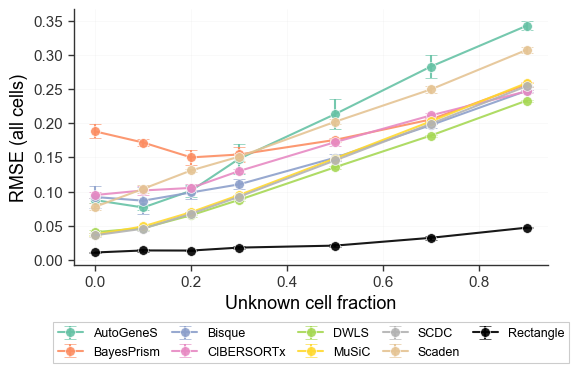

In [71]:
# Plot RMSE summary for all cells
import seaborn as sns
import matplotlib.pyplot as plt

# Modern scientific styling
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'DejaVu Sans']
plt.rcParams['pdf.fonttype'] = 42  # TrueType fonts for better PDF compatibility

fig, ax = plt.subplots(figsize=(6, 4))
ax.set_facecolor('white')
fig.patch.set_facecolor('white')

# Sort methods: alphabetically, but Rectangle last
methods = sorted(rmse_summary_all['method'].unique())
if 'Rectangle' in methods:
    methods.remove('Rectangle')
    methods.append('Rectangle')

# Plot with error bars (using standard deviation)
for method in methods:
    method_data = rmse_summary_all[rmse_summary_all['method'] == method]

    # Sort by unknown_fraction for proper line plotting
    method_data = method_data.sort_values('unknown_fraction')

    x = method_data['unknown_fraction']
    y = method_data['rmse']
    yerr = method_data['sd']

    color = method_palette.get(method, '#000000')
    ax.errorbar(x, y, yerr=yerr, label=method, marker='o', capsize=4,
                capthick=1.5, linewidth=1.5, markersize=7, markeredgewidth=0.5,
                markeredgecolor='white', color=color, alpha=0.9, zorder=3)

ax.set_xlabel('Unknown cell fraction', fontsize=13, fontweight='normal', color='black')
ax.set_ylabel('RMSE (all cells)', fontsize=13, fontweight='normal', color='black')

# Modern legend styling - horizontal layout
legend = ax.legend(bbox_to_anchor=(0.5, -0.2), loc='upper center',
                   frameon=True, fontsize=9, ncol=5,
                   framealpha=1.0, fancybox=False, columnspacing=1.0)
legend.get_frame().set_linewidth(0.8)
legend.get_frame().set_edgecolor('#CCCCCC')
legend.get_frame().set_facecolor('white')
# Ensure legend text is visible
for text in legend.get_texts():
    text.set_color('black')

# Subtle grid
ax.grid(True, alpha=0.15, linestyle='-', linewidth=0.5, color='#CCCCCC', zorder=1)
ax.set_axisbelow(True)

# Clean spines
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
for spine in ['left', 'bottom']:
    ax.spines[spine].set_color('#333333')
    ax.spines[spine].set_linewidth(1)

# Enable minor ticks
ax.minorticks_on()

# Tick styling - major ticks
ax.tick_params(axis='both', which='major', labelsize=11,
               length=4, width=1, colors='#333333',
               top=False, right=False, bottom=True, left=True,
               labeltop=False, labelright=False, labelbottom=True, labelleft=True)


plt.tight_layout()
plt.savefig('../figures/fig4c_rmse_summary_all.pdf', bbox_inches='tight', dpi=300)
plt.show()


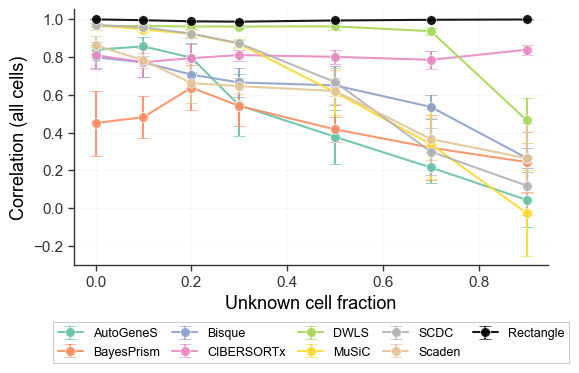

In [72]:
# Plot Correlation summary for all cells
fig, ax = plt.subplots(figsize=(6, 4))
ax.set_facecolor('white')
fig.patch.set_facecolor('white')

# Sort methods: alphabetically, but Rectangle last
methods = sorted(correlation_summary_all['method'].unique())
if 'Rectangle' in methods:
    methods.remove('Rectangle')
    methods.append('Rectangle')

# Plot with error bars (using standard deviation)
for method in methods:
    method_data = correlation_summary_all[correlation_summary_all['method'] == method]

    # Sort by unknown_fraction for proper line plotting
    method_data = method_data.sort_values('unknown_fraction')

    x = method_data['unknown_fraction']
    y = method_data['corr']
    yerr = method_data['sd']

    color = method_palette.get(method, '#000000')
    ax.errorbar(x, y, yerr=yerr, label=method, marker='o', capsize=4,
                capthick=1.5, linewidth=1.5, markersize=7, markeredgewidth=0.5,
                markeredgecolor='white', color=color, alpha=0.9, zorder=3)

ax.set_xlabel('Unknown cell fraction', fontsize=13, fontweight='normal', color='black')
ax.set_ylabel('Correlation (all cells)', fontsize=13, fontweight='normal', color='black')

# Modern legend styling - horizontal layout
legend = ax.legend(bbox_to_anchor=(0.5, -0.2), loc='upper center',
                   frameon=True, fontsize=9, ncol=5,
                   framealpha=1.0, fancybox=False, columnspacing=1.0)
legend.get_frame().set_linewidth(0.8)
legend.get_frame().set_edgecolor('#CCCCCC')
legend.get_frame().set_facecolor('white')
# Ensure legend text is visible
for text in legend.get_texts():
    text.set_color('black')

# Subtle grid
ax.grid(True, alpha=0.15, linestyle='-', linewidth=0.5, color='#CCCCCC', zorder=1)
ax.set_axisbelow(True)

ax.set_ylim([-0.3, 1.05])

# Clean spines
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
for spine in ['left', 'bottom']:
    ax.spines[spine].set_color('#333333')
    ax.spines[spine].set_linewidth(1)

# Enable minor ticks
ax.minorticks_on()

# Tick styling - major ticks
ax.tick_params(axis='both', which='major', labelsize=11,
               length=4, width=1, colors='#333333',
               top=False, right=False, bottom=True, left=True,
               labeltop=False, labelright=False, labelbottom=True, labelleft=True)


plt.tight_layout()
plt.savefig('../figures/fig4c_correlation_summary_all.pdf', bbox_inches='tight', dpi=300)
plt.show()


# MRNA BIAS

In [2]:
adata_hao_sub = anndata.read_h5ad('../data/haoSub_adata.h5ad')
sc_data_muris = pd.read_pickle("../data/sc_data_tabula_muris.pkl")
annotations = pd.read_csv("../data/annotations_tabula_muris.csv", index_col=0)
annotations = annotations['0']
annotations = pd.Series(annotations, index=sc_data_muris.columns)
adata_muris = AnnData(sc_data_muris.T, obs=annotations.to_frame(name="cell_type"))

bulks_chen = pd.read_csv("../data/bulks_chen_tpm.csv", index_col=0)
bulks_peti = pd.read_csv("../data/bulks_petitprez_tpm.csv", index_col=0)
bulks_fino = pd.read_csv("../data/fig2/finotello/bulks_finotello_tpm.csv", index_col=0)
bulks_hoek = pd.read_csv("../data/bulks_hoek_tpm.csv", index_col=0)
bulks_morandini = pd.read_csv("../data/fig2/morandini/morandini_tpm.csv.gz", index_col=0)
bulks_altman = pd.read_csv("../data/fig2/altman/altman_tpm.csv.gz", index_col=0)



In [3]:
estimations_fino_no_bias, signature_results_fino_no_bias = rp.rectangle(adata_hao_sub, bulks_fino.T, correct_mrna_bias=False)
estimations_fino_no_bias.to_csv("../output/estimations_fino_no_bias.csv")


2026-01-10 09:11:53.142 | INFO     | rectanglepy.pp.create_signature:build_rectangle_signatures:327 - Using 12872 common genes between bulks and single-cell data
2026-01-10 09:11:54.943 | INFO     | rectanglepy.pp.create_signature:_de_analysis:200 - Starting DE analysis
2026-01-10 09:11:57.213 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for B cells
2026-01-10 09:12:00.197 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for ILC
2026-01-10 09:12:01.145 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for Monocytes
2026-01-10 09:12:02.582 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for NK cells
2026-01-10 09:12:03.459 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for Plasma cells
2026-01-10 09:12:04.072 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for Platelet
2026-01-10

In [4]:
estimations_fino_no_bias = pd.read_csv("../output/estimations_fino_no_bias.csv", index_col=0)

<Axes: title={'center': 'Finotello'}, xlabel='True Fractions', ylabel='Estimated Fractions'>

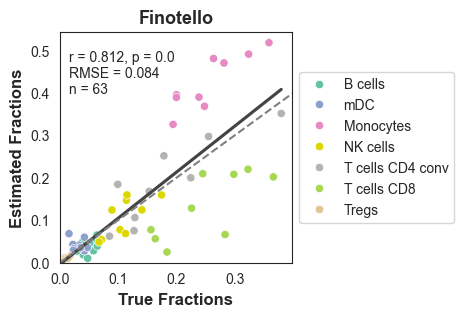

In [5]:
finotello_gld = pd.read_csv('../data/finotello_facs.csv', index_col=0).T
finotello_gld = finotello_gld.fillna(0)
finotello_gld.columns = ["NK cells", 'B cells', 'Tregs', 'mDC', 'Monocytes', 'Neutrophilss', 'T cells CD8',
                         'T cells CD4 conv', 'Other']
finotello_gld = finotello_gld.T
gld_m, finotello_m = helper.match_dfs(finotello_gld, estimations_fino_no_bias.T)
gld_m = gld_m.sort_index(key=lambda x: x.str.lower())
finotello_m = finotello_m.sort_index(key=lambda x: x.str.lower())
evaluation_fintotello_rectangle = helper.create_evaluation_df(gld_m, finotello_m)
rsme_finotello_rectangle, r_finotello_rectangle, p_finotello_rectangle = helper.evaulate_total_df(
    evaluation_fintotello_rectangle)
rsmes_f_rectangle, ps_f_rectangle, rs_f_rectangle = helper.evaluate_by_cell_type(gld_m, finotello_m)
helper.create_scatter_plot_total(evaluation_fintotello_rectangle, rsme_finotello_rectangle, p_finotello_rectangle,
                                 r_finotello_rectangle,
                                 'Finotello', save_path='../figures/fig4_fino_no_bias.pdf', size=(3, 3))

In [8]:
estimations_hoek_no_bias, signature_results_hoek_no_bias = rp.rectangle(adata_hao_sub, bulks_hoek.T, correct_mrna_bias=False)
estimations_hoek_no_bias.to_csv("../output/estimations_hoek_no_bias.csv")


2026-01-10 09:38:45.948 | INFO     | rectanglepy.pp.create_signature:build_rectangle_signatures:327 - Using 12872 common genes between bulks and single-cell data
2026-01-10 09:38:48.146 | INFO     | rectanglepy.pp.create_signature:_de_analysis:200 - Starting DE analysis
2026-01-10 09:38:51.053 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for B cells
2026-01-10 09:38:53.375 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for ILC
2026-01-10 09:38:54.569 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for Monocytes
2026-01-10 09:38:56.016 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for NK cells
2026-01-10 09:38:56.886 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for Plasma cells
2026-01-10 09:38:57.660 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for Platelet
2026-01-10

In [11]:
estimations_hoek = pd.read_csv("../output/estimations_hoek_no_bias.csv", index_col=0)

<Axes: title={'center': 'Hoek'}, xlabel='True Fractions', ylabel='Estimated Fractions'>

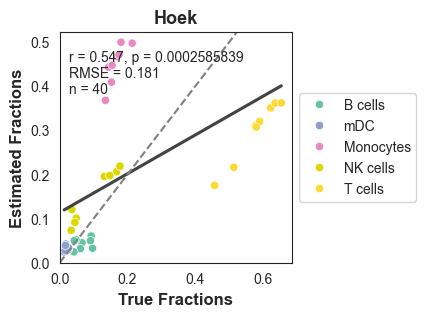

In [12]:
hoek_gld = pd.read_csv('../data/hoek_facs.csv', index_col=0).T
hoek_gld = hoek_gld.fillna(0)
hoek_gld.columns = ["T cells", 'Monocytes', 'B cells', 'mDC', 'NK cells']
hoek_gld = hoek_gld.T


estimations_hoek['T cells'] = estimations_hoek['T cells CD4 conv'] + estimations_hoek['T cells CD8'] + estimations_hoek[
    'Tregs']

estimations_hoek = estimations_hoek.T

gld_hoek_m, hoek_m = helper.match_dfs(hoek_gld, estimations_hoek)
gld_hoek_m = gld_hoek_m.sort_index(key=lambda x: x.str.lower())
hoek_m = hoek_m.sort_index(key=lambda x: x.str.lower())
evaluation_hoek = helper.create_evaluation_df(gld_hoek_m, hoek_m)
rsme_hoek, r_hoek, p_hoek = helper.evaulate_total_df(evaluation_hoek)
rsmes_h, ps_h, rs_h = helper.evaluate_by_cell_type(gld_hoek_m, hoek_m)
helper.create_scatter_plot_total(evaluation_hoek, rsme_hoek, p_hoek, r_hoek, 'Hoek', save_path='../figures/fig2a_hoek_no_bias.pdf', size=(3, 3))

In [13]:
estimations_chen_no_bias, signature_results_chen_no_bias = rp.rectangle(adata_muris, bulks_chen.T, correct_mrna_bias=False)
estimations_chen_no_bias.to_csv("../output/estimations_chen_no_bias.csv")

2026-01-10 09:39:50.465 | INFO     | rectanglepy.pp.create_signature:build_rectangle_signatures:327 - Using 10978 common genes between bulks and single-cell data
2026-01-10 09:39:51.630 | INFO     | rectanglepy.pp.create_signature:_de_analysis:200 - Starting DE analysis
2026-01-10 09:39:52.912 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for B cells
2026-01-10 09:39:55.072 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for Macrophages
2026-01-10 09:39:55.799 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for NK cells
2026-01-10 09:39:56.462 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for T cells CD4 conv
2026-01-10 09:39:57.150 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for T cells CD8
2026-01-10 09:39:57.780 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for Tregs

In [14]:
estimations_chen = pd.read_csv("../output/estimations_chen_no_bias.csv", index_col=0)

<Axes: title={'center': 'Chen'}, xlabel='True Fractions', ylabel='Estimated Fractions'>

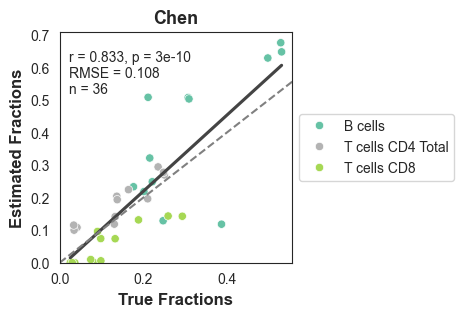

In [15]:
chen_gld = pd.read_csv('../data/chen_facs.csv', index_col=0).T
chen_gld = chen_gld.fillna(0)
chen_gld.columns = ["Monocytes", "B cells", 'T cells CD8', 'T cells CD4 Total']
chen_t = estimations_chen
chen_t['T cells CD4 Total'] = chen_t['T cells CD4 conv'] + chen_t['Tregs']
chen_m, gld_m = helper.match_dfs(chen_t,chen_gld)
# sort alphabetically reverse
gld_m = gld_m.sort_index(key=lambda x: x.str.lower(), ascending=True)
chen_m = chen_m.sort_index(key=lambda x: x.str.lower(), ascending=True)
evaluation_chen = helper.create_evaluation_df(gld_m.T, chen_m.T)
# sort by index alphabetically ignore case
evaluation_chen = evaluation_chen.sort_values(by='Cell type', key=lambda x: x.str.lower())
rsme_chen, r_chen, p_chen = helper.evaulate_total_df(evaluation_chen)
rsmes_chen, ps_chen, rs_chen = helper.evaluate_by_cell_type(gld_m.T, chen_m.T)

helper.create_scatter_plot_total(evaluation_chen, rsme_chen, p_chen, r_chen, 'Chen', save_path='../figures/fig2a_chen_no_bias.pdf', size=(3, 3))

In [16]:
estimations_peti_no_bias, signature_results_peti_no_bias = rp.rectangle(adata_muris, bulks_peti.T, correct_mrna_bias=False)
estimations_peti_no_bias.to_csv("../output/estimations_peti_no_bias.csv")

2026-01-10 09:46:26.362 | INFO     | rectanglepy.pp.create_signature:build_rectangle_signatures:327 - Using 10978 common genes between bulks and single-cell data
2026-01-10 09:46:27.650 | INFO     | rectanglepy.pp.create_signature:_de_analysis:200 - Starting DE analysis
2026-01-10 09:46:28.948 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for B cells
2026-01-10 09:46:31.039 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for Macrophages
2026-01-10 09:46:31.707 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for NK cells
2026-01-10 09:46:32.407 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for T cells CD4 conv
2026-01-10 09:46:33.023 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for T cells CD8
2026-01-10 09:46:33.851 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for Tregs

In [17]:
estimations_peti = pd.read_csv("../output/estimations_peti_no_bias.csv", index_col=0)

<Axes: title={'center': 'Petitprez'}, xlabel='True Fractions', ylabel='Estimated Fractions'>

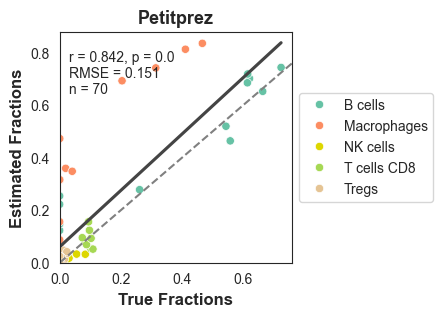

In [18]:
petitprez_gld = pd.read_csv('../data/petitprez_facs.csv', index_col=0).T
petitprez_gld = petitprez_gld.fillna(0)

# replace nan with 0
petitprez_gld = petitprez_gld.fillna(0)

petitprez_gld.columns = ["T cells", 'T cells CD8', 'B cells', 'Tregs', 'NK cells', 'B cells ger', 'Basophils', 'Mast',
                         'Macrophages', 'Eosinophils', 'Neutrophils', 'Monocytes', 'B derived', 'Mono Macro', 'NK_or_T',
                         'Granulocytes']
# drop columns
petitprez_gld = petitprez_gld.drop(['T cells'], axis=1)

# sort by index alphabetically ignore case
petitprez_gld = petitprez_gld.sort_index(key=lambda x: x.str.lower())
estimations_peti = estimations_peti.sort_index(key=lambda x: x.str.lower())


gld_m, petitprez_m = helper.match_dfs(petitprez_gld, estimations_peti)
evaluation_petitprez = helper.create_evaluation_df(gld_m.T, petitprez_m.T)
# sort by index alphabetically ignore case
evaluation_petitprez = evaluation_petitprez.sort_values(by='Cell type', key=lambda x: x.str.lower())
rsme_peptirez, r_peptirez, p_peptirez = helper.evaulate_total_df(evaluation_petitprez)
rsmes_pept, ps_pept, rs_pept = helper.evaluate_by_cell_type(gld_m.T, petitprez_m.T)

helper.create_scatter_plot_total(evaluation_petitprez, rsme_peptirez, p_peptirez, r_peptirez, 'Petitprez',
                                 save_path='../figures/fig2a_petitprez_no_bias.pdf', size=(3, 3))


In [19]:
estimations_morandini_no_bias, signature_results_morandini_no_bias = rp.rectangle(adata_hao_sub, bulks_morandini.T, correct_mrna_bias=False)
estimations_morandini_no_bias.to_csv("../output/estimations_morandini_no_bias.csv")

2026-01-10 09:55:25.770 | INFO     | rectanglepy.pp.create_signature:build_rectangle_signatures:327 - Using 7593 common genes between bulks and single-cell data
2026-01-10 09:55:27.544 | INFO     | rectanglepy.pp.create_signature:_de_analysis:200 - Starting DE analysis
2026-01-10 09:55:29.343 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for B cells
2026-01-10 09:55:31.777 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for ILC
2026-01-10 09:55:33.088 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for Monocytes
2026-01-10 09:55:34.028 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for NK cells
2026-01-10 09:55:34.691 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for Plasma cells
2026-01-10 09:55:35.259 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for Platelet
2026-01-10 

In [20]:
estimations_morandini = pd.read_csv("../output/estimations_morandini_no_bias.csv", index_col=0)

<Axes: title={'center': 'Morandini'}, xlabel='True Fractions', ylabel='Estimated Fractions'>

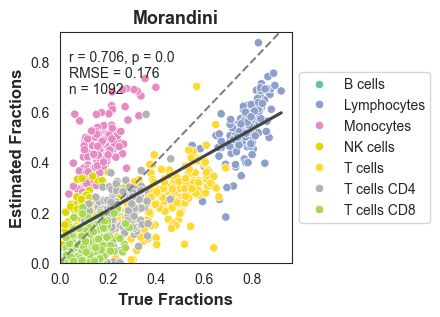

In [21]:
estimations_morandini['T cells CD4'] = estimations_morandini['T cells CD4 conv']
estimations_morandini['T cells'] = estimations_morandini['T cells CD4 conv'] + estimations_morandini['T cells CD8'] + \
                                   estimations_morandini[
                                       'Tregs']
estimations_morandini['Lymphocytes'] = estimations_morandini['T cells'] + estimations_morandini['NK cells'] + \
                                       estimations_morandini['ILC'] + estimations_morandini['B cells'] + \
                                       estimations_morandini['Plasma cells']
estimations_morandini['Monocytes'] = estimations_morandini['Monocytes'] + estimations_morandini['pDC'] + \
                                     estimations_morandini['mDC']
estimations_morandini = estimations_morandini.T
morandini_facs = pd.read_csv('../data/fig2/morandini/morandini_facs.csv', index_col=0)
morandini_facs = morandini_facs.T

gld_m, morandini_m = helper.match_dfs(morandini_facs.T, estimations_morandini)

gld_m = gld_m.sort_index(key=lambda x: x.str.lower())
morandini_m = morandini_m.sort_index(key=lambda x: x.str.lower())
evaluation_morandini = helper.create_evaluation_df(gld_m, morandini_m)
rsme_morandini, r_morandini, p_morandini = helper.evaulate_total_df(evaluation_morandini)
rsmes_morandini, ps_morandini, rs_morandini = helper.evaluate_by_cell_type(gld_m, morandini_m)
helper.create_scatter_plot_total(evaluation_morandini, rsme_morandini, p_morandini, r_morandini,
                                 'Morandini', save_path='../figures/fig2a_morandini_no_bias.pdf', size=(3, 3))

In [22]:
estimations_altman_no_bias, signature_results_altman_no_bias = rp.rectangle(adata_hao_sub, bulks_altman.T, correct_mrna_bias=False)
estimations_altman_no_bias.to_csv("../output/estimations_altman_no_bias.csv")

2026-01-10 10:02:10.471 | INFO     | rectanglepy.pp.create_signature:build_rectangle_signatures:327 - Using 14522 common genes between bulks and single-cell data
2026-01-10 10:02:13.055 | INFO     | rectanglepy.pp.create_signature:_de_analysis:200 - Starting DE analysis
2026-01-10 10:02:16.456 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for B cells
2026-01-10 10:02:17.371 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for ILC
2026-01-10 10:02:18.868 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for Monocytes
2026-01-10 10:02:20.402 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for NK cells
2026-01-10 10:02:21.395 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for Plasma cells
2026-01-10 10:02:22.193 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for Platelet
2026-01-10

In [24]:
estimations_altman = pd.read_csv("../output/estimations_altman_no_bias.csv", index_col=0)

<Axes: title={'center': 'Altman'}, xlabel='True Fractions', ylabel='Estimated Fractions'>

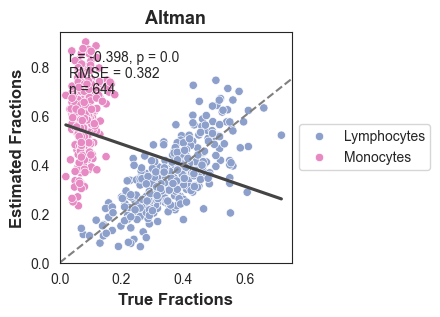

In [25]:
estimations_altman['Lymphocytes'] = estimations_altman['T cells CD4 conv'] + estimations_altman['T cells CD8'] + \
                                    estimations_altman[
                                        'Tregs'] + estimations_altman['B cells'] + estimations_altman['NK cells'] + \
                                    estimations_altman['ILC']
estimations_altman['Plasma cells'] = estimations_altman['Lymphocytes'] + estimations_altman['Plasma cells']
estimations_altman['Monocytes'] = estimations_altman['Monocytes'] + estimations_altman['mDC'] + estimations_altman[
    'pDC']
estimations_altman = estimations_altman.T
altman_facs = pd.read_csv('../data/fig2/altman/altman_facs.csv', index_col=0)
altman_facs = altman_facs.T
gld_m, altman_m = helper.match_dfs(altman_facs.T, estimations_altman)
gld_m = gld_m.sort_index(key=lambda x: x.str.lower())
altman_m = altman_m.sort_index(key=lambda x: x.str.lower())
evaluation_altman = helper.create_evaluation_df(gld_m, altman_m)
rsme_altman, r_altman, p_altman = helper.evaulate_total_df(evaluation_altman)
rsmes_altman, ps_altman, rs_altman = helper.evaluate_by_cell_type(gld_m, altman_m)
helper.create_scatter_plot_total(evaluation_altman, rsme_altman, p_altman, r_altman,
                                 'Altman', save_path='../figures/fig2a_altman_no_bias.pdf', size=(3, 3))